# 05 – Modeller: SVM, Random Forest ve XGBoost

Bu notebook **makine öğrenmesi modelleri** bölümünün ikinci kısmını kapsar: SVM, Random Forest ve XGBoost için hiperparametre araması, overfitting kontrolü ve öğrenme eğrileri.

- Yöntem 04 ile aynıdır: hiperparametre seçimi train üzerinde **5 katlı stratified cross-validation** ile, **phishing F1** skoruna göre yapılır.
- Test verisi bu notebook'ta kullanılmaz.
- SMOTE kullanılmaz (03'te fayda sağlamadığı gösterildi).

Girdi: `outputs/X_train.csv`, `outputs/y_train.csv`
Çıktı: `outputs/cv_results_svm.csv`, `cv_results_rf.csv`, `cv_results_xgb.csv`, `outputs/models/best_svm.pkl`, `best_rf.pkl`, `best_xgb.pkl`; en iyi sonuçlar `en_iyi_parametreler.csv` dosyasına eklenir.

## 1. Kurulum

XGBoost kurulu değilse aşağıdaki satırın başındaki `#` işaretini kaldırıp bir kez çalıştırın, ardından kernel'i yeniden başlatın.

In [1]:
#%pip install xgboost

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score, recall_score, precision_score
from xgboost import XGBClassifier

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/models", exist_ok=True)

def grafik_kaydet(ad):
    # O anki grafiği rapor için PNG olarak kaydeder
    plt.savefig(f"outputs/figures/{ad}.png", dpi=150, bbox_inches="tight")

## 2. Verinin yüklenmesi

**XGBoost** sınıf etiketlerinin 0 ve 1 olmasını şart koşar. Bu yüzden XGBoost için etiketler dönüştürülür: **phishing (-1) → 1, normal (1) → 0**. Diğer modeller orijinal etiketlerle eğitilir. 06'da XGBoost tahminleri tekrar -1/1'e çevrilecektir.

In [2]:
X_train = pd.read_csv("outputs/X_train.csv")
y_train = pd.read_csv("outputs/y_train.csv").squeeze()

# XGBoost etiketlerin 0/1 olmasını ister: phishing (-1) → 1, normal (1) → 0
y_train_xgb = (y_train == -1).astype(int)

print("Train:", X_train.shape)

Train: (4617, 31)


## 3. Değerlendirme ayarları

Metrikler phishing sınıfına göre hesaplanır. Phishing etiketi SVM ve RF'de -1, XGBoost'ta 1 olduğu için iki ayrı metrik seti tanımlanır. Böylece F1 skorları tüm modellerde aynı anlamı taşır.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # 04 ile aynı katlar

def skorlar_olustur(phishing_etiketi):
    # Phishing sınıfının etiketine göre metrikleri tanımlar
    return {
        "f1": make_scorer(f1_score, pos_label=phishing_etiketi),
        "recall": make_scorer(recall_score, pos_label=phishing_etiketi),
        "precision": make_scorer(precision_score, pos_label=phishing_etiketi),
        "accuracy": "accuracy",
        "roc_auc": "roc_auc",
    }

skorlar = skorlar_olustur(-1)       # SVM ve RF: phishing = -1
skorlar_xgb = skorlar_olustur(1)    # XGBoost: phishing = 1

## 4. Yardımcı fonksiyonlar

04'teki fonksiyonların aynısıdır, yalnızca hedef değişken ve metrikler parametre olarak verilir. Sonuç dosyaları zaten varsa arama tekrarlanmaz, yeniden aramak için `yeniden=True` verilir.

In [4]:
def ara_ve_kaydet(ad, model, param_grid, y, skor, yeniden=False):
    # Grid search yapar; sonuçları CSV'ye, en iyi modeli .pkl'ye kaydeder. Dosyalar varsa tekrar aramaz.
    csv_yolu = f"outputs/cv_results_{ad}.csv"
    model_yolu = f"outputs/models/best_{ad}.pkl"

    if os.path.exists(csv_yolu) and os.path.exists(model_yolu) and not yeniden:
        print(f"{ad}: kayıtlı sonuçlar yüklendi (yeniden eğitilmedi)")
        return pd.read_csv(csv_yolu), joblib.load(model_yolu)

    gs = GridSearchCV(model, param_grid, scoring=skor, refit="f1", cv=cv,
                      return_train_score=True, n_jobs=-1)
    gs.fit(X_train, y)

    pd.DataFrame(gs.cv_results_).to_csv(csv_yolu, index=False)
    joblib.dump(gs.best_estimator_, model_yolu)
    print(f"{ad}: {len(gs.cv_results_['params'])} kombinasyon denendi, en iyi validation F1 = {gs.best_score_:.4f}")
    return pd.read_csv(csv_yolu), gs.best_estimator_   # her iki durumda da CSV'den okunur, tipler aynı olur

def en_iyi_satir(sonuc):
    # Validation F1'e göre 1. sıradaki parametre kombinasyonu
    return sonuc.loc[sonuc["rank_test_f1"].idxmin()]

def ozet_kaydet(ad, sonuc):
    s = en_iyi_satir(sonuc)
    satir = {"model": ad, "parametreler": s["params"],
             **{f"val_{m}": round(s[f"mean_test_{m}"], 4) for m in skorlar},
             "train_f1": round(s["mean_train_f1"], 4),
             "fit_suresi_sn": round(s["mean_fit_time"], 3)}
    yol = "outputs/en_iyi_parametreler.csv"
    ozet = pd.read_csv(yol) if os.path.exists(yol) else pd.DataFrame()
    if len(ozet):
        ozet = ozet[ozet["model"] != ad]      # aynı model daha önce yazıldıysa eski satırı sil
    ozet = pd.concat([ozet, pd.DataFrame([satir])], ignore_index=True)
    ozet.to_csv(yol, index=False)
    return pd.DataFrame([satir])

## 5. SVM (Support Vector Machine)

İki sınıfı birbirinden en geniş marjla ayıran sınırı bulur. Denenen parametreler:
- `kernel`: `linear` doğrusal sınır, `rbf` doğrusal olmayan (eğri) sınır çizer.
- `C`: hatalı sınıflandırmanın cezası. Büyük C eğitim verisine daha sıkı uyar ve overfitting riskini artırır.
- `gamma`: rbf çekirdeğinde tek bir örneğin etki alanı. Büyük gamma daha karmaşık sınırlar üretir.

Mesafe tabanlı olduğu için özellikler pipeline içinde standartlaştırılır.

In [5]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),       # SVM mesafe tabanlı, ölçekleme gerekli
    ("model", SVC()),
])
# gamma sadece rbf çekirdeğinde anlamlı olduğu için iki ayrı ızgara
svm_grid = [
    {"model__kernel": ["linear"], "model__C": [0.1, 1, 10]},
    {"model__kernel": ["rbf"], "model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", 0.01, 0.1]},
]
svm_sonuc, best_svm = ara_ve_kaydet("svm", svm_model, svm_grid, y_train, skorlar)
ozet_kaydet("svm", svm_sonuc)

svm: 15 kombinasyon denendi, en iyi validation F1 = 0.9548


,model,parametreler,val_f1,val_recall,val_precision,val_accuracy,val_roc_auc,train_f1,fit_suresi_sn
0,svm,"{'model__C': 1, 'model__gamma': 0.1, 'model__k...",0.9548,0.9541,0.9554,0.9534,0.9833,0.9822,3.21


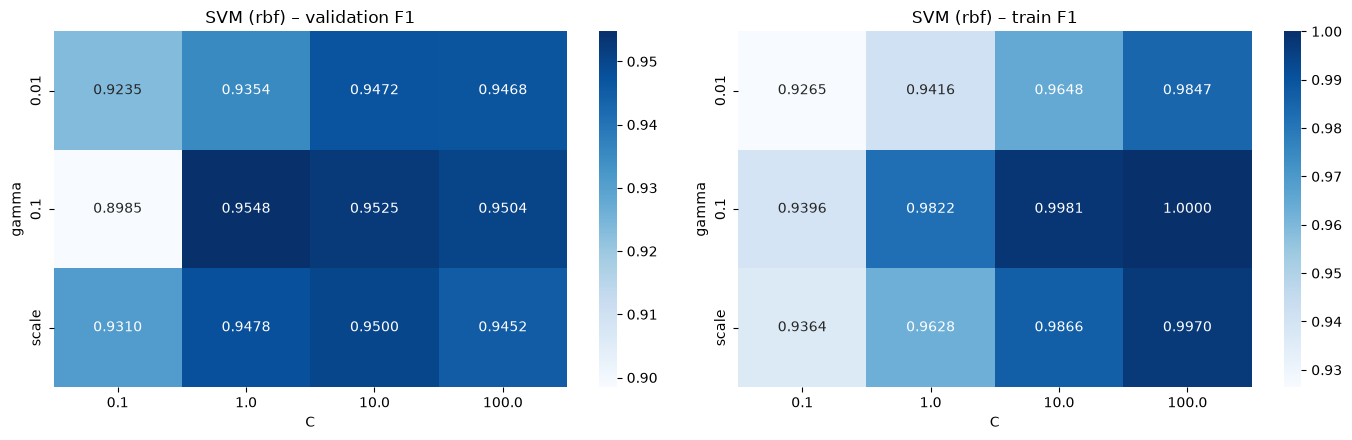

,param_model__C,mean_test_f1,mean_train_f1
0,0.1,0.927045,0.928967
1,1.0,0.926084,0.929178
2,10.0,0.926707,0.929606


In [6]:
rbf = svm_sonuc[svm_sonuc["param_model__kernel"] == "rbf"].astype({"param_model__gamma": str})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (sutun, baslik) in zip(axes, [("mean_test_f1", "validation"), ("mean_train_f1", "train")]):
    tablo = rbf.pivot_table(index="param_model__gamma", columns="param_model__C", values=sutun)
    sns.heatmap(tablo, annot=True, fmt=".4f", cmap="Blues", ax=ax)
    ax.set_title(f"SVM (rbf) – {baslik} F1")
    ax.set_xlabel("C")
    ax.set_ylabel("gamma")
plt.tight_layout()
grafik_kaydet("svm_parametre_f1")
plt.show()

# Doğrusal çekirdek sonuçları
svm_sonuc[svm_sonuc["param_model__kernel"] == "linear"][["param_model__C", "mean_test_f1", "mean_train_f1"]]

## 6. Random Forest

Birbirinden bağımsız çok sayıda karar ağacı eğitir ve tahmini ağaçların oylamasıyla yapar. Her ağaç verinin ve özelliklerin rastgele bir alt kümesini gördüğü için ağaçlar birbirinden farklılaşır, bu da tek bir ağacın ezberleme eğilimini azaltır.

Ağaç tabanlı olduğu için ölçeklemeye gerek yoktur. `max_depth` ve `min_samples_leaf` ağaçların karmaşıklığını sınırlayarak overfitting'i kontrol eder.

In [7]:
# n_jobs=1: paralellik GridSearchCV tarafında yapılır
rf_model = RandomForestClassifier(random_state=42, n_jobs=1)
rf_grid = {
    "n_estimators": [100, 300],          # ağaç sayısı
    "max_depth": [5, 10, 20, None],      # None = sınırsız derinlik
    "min_samples_leaf": [1, 2, 5],       # yapraktaki en az örnek sayısı
    "max_features": ["sqrt", "log2"],    # her bölünmede bakılan özellik sayısı
}
rf_sonuc, best_rf = ara_ve_kaydet("rf", rf_model, rf_grid, y_train, skorlar)
ozet_kaydet("rf", rf_sonuc)

rf: 48 kombinasyon denendi, en iyi validation F1 = 0.9610


,model,parametreler,val_f1,val_recall,val_precision,val_accuracy,val_roc_auc,train_f1,fit_suresi_sn
0,rf,"{'max_depth': 20, 'max_features': 'log2', 'min...",0.961,0.9579,0.9641,0.9599,0.9924,1.0,1.709


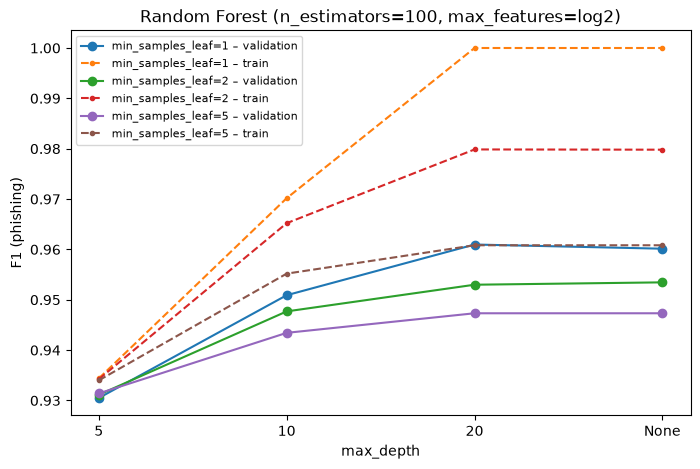

In [8]:
# En iyi n_estimators ve max_features sabit tutularak derinlik ve yaprak boyutunun etkisi
rf_grafik = rf_sonuc.assign(max_depth=rf_sonuc["param_max_depth"].fillna(0).astype(int).astype(str).replace("0", "None"))
en_iyi = en_iyi_satir(rf_sonuc)
secili = rf_grafik[(rf_grafik["param_n_estimators"] == en_iyi["param_n_estimators"]) &
                   (rf_grafik["param_max_features"] == en_iyi["param_max_features"])]

fig, ax = plt.subplots(figsize=(8, 5))
for leaf, grup in secili.groupby("param_min_samples_leaf"):
    ax.plot(grup["max_depth"], grup["mean_test_f1"], marker="o", label=f"min_samples_leaf={leaf} – validation")
    ax.plot(grup["max_depth"], grup["mean_train_f1"], marker=".", linestyle="--", label=f"min_samples_leaf={leaf} – train")
ax.set_xlabel("max_depth")
ax.set_ylabel("F1 (phishing)")
ax.set_title(f"Random Forest (n_estimators={en_iyi['param_n_estimators']}, max_features={en_iyi['param_max_features']})")
ax.legend(fontsize=8)
grafik_kaydet("rf_parametre_f1")
plt.show()

## 7. XGBoost

Karar ağaçlarını **sırayla** eğitir: her yeni ağaç, önceki ağaçların hatalarını düzeltmeyi öğrenir ve son tahmin tüm ağaçların katkılarının toplamıdır (boosting). Random Forest'taki bağımsız ağaçların aksine ağaçlar sığdır ve birbirini tamamlar.

- `learning_rate`: her ağacın katkısının küçültülme oranı. Küçük değer daha dengeli öğrenme sağlar.
- `subsample` < 1: her ağacın verinin bir kısmıyla eğitilmesi, overfitting'i azaltır.

In [9]:
xgb_model = XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=1)
xgb_grid = {
    "n_estimators": [100, 300],          # ağaç sayısı
    "max_depth": [3, 5, 7],              # her ağacın derinliği
    "learning_rate": [0.05, 0.1, 0.3],   # her ağacın katkı oranı
    "subsample": [0.8, 1.0],             # her ağaçta kullanılan örnek oranı
}
xgb_sonuc, best_xgb = ara_ve_kaydet("xgb", xgb_model, xgb_grid, y_train_xgb, skorlar_xgb)
ozet_kaydet("xgb", xgb_sonuc)

xgb: 36 kombinasyon denendi, en iyi validation F1 = 0.9605


,model,parametreler,val_f1,val_recall,val_precision,val_accuracy,val_roc_auc,train_f1,fit_suresi_sn
0,xgb,"{'learning_rate': 0.3, 'max_depth': 5, 'n_esti...",0.9605,0.9571,0.9641,0.9595,0.9937,0.9956,0.567


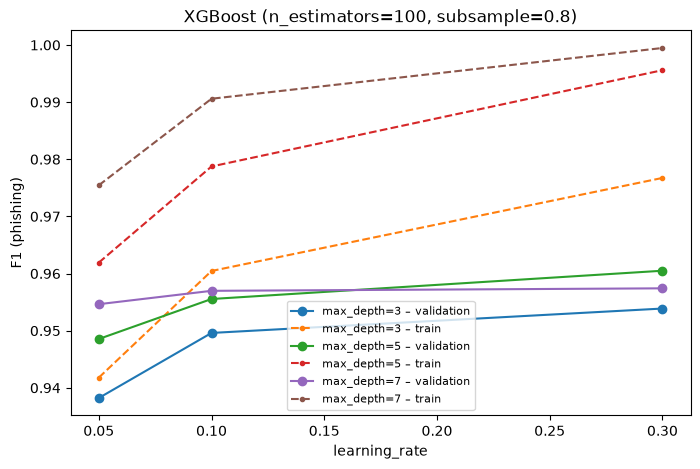

In [10]:
# En iyi n_estimators ve subsample sabit tutularak derinlik ve learning rate'in etkisi
en_iyi = en_iyi_satir(xgb_sonuc)
secili = xgb_sonuc[(xgb_sonuc["param_n_estimators"] == en_iyi["param_n_estimators"]) &
                   (xgb_sonuc["param_subsample"] == en_iyi["param_subsample"])]

fig, ax = plt.subplots(figsize=(8, 5))
for depth, grup in secili.groupby("param_max_depth"):
    grup = grup.sort_values("param_learning_rate")
    ax.plot(grup["param_learning_rate"], grup["mean_test_f1"], marker="o", label=f"max_depth={depth} – validation")
    ax.plot(grup["param_learning_rate"], grup["mean_train_f1"], marker=".", linestyle="--", label=f"max_depth={depth} – train")
ax.set_xlabel("learning_rate")
ax.set_ylabel("F1 (phishing)")
ax.set_title(f"XGBoost (n_estimators={en_iyi['param_n_estimators']}, subsample={en_iyi['param_subsample']})")
ax.legend(fontsize=8)
grafik_kaydet("xgb_parametre_f1")
plt.show()

## 8. Overfitting kontrolü

En iyi parametrelerde train ve validation F1 karşılaştırılır.

> Ağaç modellerinde (RF, XGBoost) train F1'in 1,0'a yakın çıkması, ağaçların eğitim verisini tamamen ayırabildiğini gösterir. Asıl ölçü validation skorudur. Düzenlileştirici parametreler (`max_depth`, `min_samples_leaf`, `subsample`, `C`, `gamma`) grid'e dahil edilmiş ve seçim validation skoruna göre yapılmıştır. Parametre grafiklerinde karmaşıklık arttıkça validation skorunun düşüp düşmediği incelenebilir.

In [11]:
overfit = pd.DataFrame([{
    "model": ad,
    "train_f1": en_iyi_satir(s)["mean_train_f1"],
    "validation_f1": en_iyi_satir(s)["mean_test_f1"],
} for ad, s in [("SVM", svm_sonuc), ("Random Forest", rf_sonuc), ("XGBoost", xgb_sonuc)]])
overfit["fark"] = overfit["train_f1"] - overfit["validation_f1"]
overfit.round(4)

,model,train_f1,validation_f1,fark
0,SVM,0.9822,0.9548,0.0274
1,Random Forest,1.0000,0.9610,0.0390
2,XGBoost,0.9956,0.9605,0.0351


### 8.1 Öğrenme eğrileri

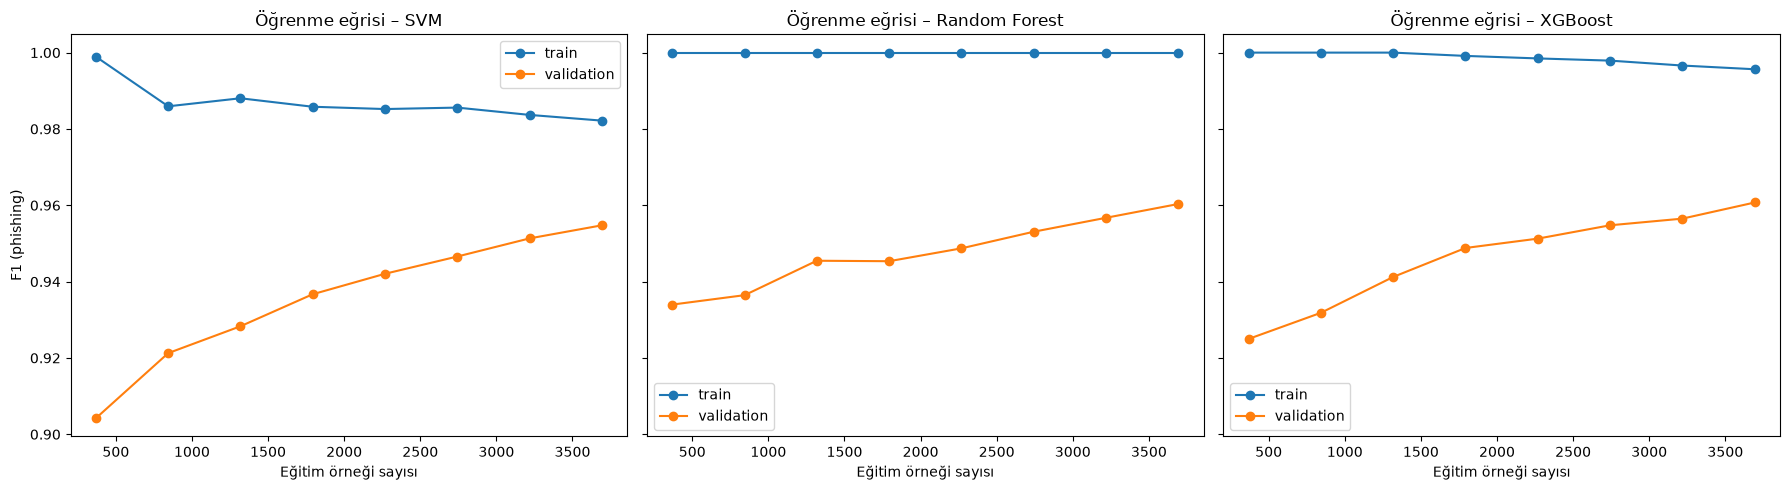

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (ad, model, y, skor) in zip(axes, [
        ("SVM", best_svm, y_train, skorlar["f1"]),
        ("Random Forest", best_rf, y_train, skorlar["f1"]),
        ("XGBoost", best_xgb, y_train_xgb, skorlar_xgb["f1"])]):
    boyut, train_skor, val_skor = learning_curve(
        model, X_train, y, cv=cv, scoring=skor,
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
    ax.plot(boyut, train_skor.mean(axis=1), marker="o", label="train")
    ax.plot(boyut, val_skor.mean(axis=1), marker="o", label="validation")
    ax.set_title(f"Öğrenme eğrisi – {ad}")
    ax.set_xlabel("Eğitim örneği sayısı")
    ax.legend()
axes[0].set_ylabel("F1 (phishing)")
plt.tight_layout()
grafik_kaydet("ogrenme_egrisi_svm_rf_xgb")
plt.show()

## 9. Özet

04 ve 05'te seçilen beş modelin en iyi parametreleri ve validation skorları. Test değerlendirmesi ve karşılaştırma `06` notebook'unda yapılacaktır.

In [13]:
pd.read_csv("outputs/en_iyi_parametreler.csv")

,model,parametreler,val_f1,val_recall,val_precision,val_accuracy,val_roc_auc,train_f1,fit_suresi_sn
0,lr,"{'model__C': 0.1, 'model__penalty': 'l2'}",0.9286,0.9243,0.9333,0.9268,0.9789,0.9288,0.123
1,knn,"{'model__metric': 'manhattan', 'model__n_neigh...",0.9494,0.9474,0.9514,0.9480,0.9861,1.0000,0.046
2,svm,"{'model__C': 1, 'model__gamma': 0.1, 'model__k...",0.9548,0.9541,0.9554,0.9534,0.9833,0.9822,3.210
3,rf,"{'max_depth': 20, 'max_features': 'log2', 'min...",0.9610,0.9579,0.9641,0.9599,0.9924,1.0000,1.709
4,xgb,"{'learning_rate': 0.3, 'max_depth': 5, 'n_esti...",0.9605,0.9571,0.9641,0.9595,0.9937,0.9956,0.567
